In [1]:
# need to take averages of fluxes over all dumps, then convert to Luminosity, then plot (see Baraffe, 2021)

In [2]:
import numpy as np
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
r_sun = 6.9570000000000000E+010
r_tot = 5.7671763407229273 * r_sun
r_bot = 52239320762.259705
r_top = 175414301920.61127
Nr = 512
# Ntheta = 360
# Nphi = 720
dr_grid = (r_top - r_bot) / Nr
r_env_init = 0.2836686568328816 * r_tot

In [4]:
absolute_path = "/z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc*"

PATTERN = os.path.relpath(absolute_path)

all_files = sorted(glob.glob(PATTERN))

# all_files[0:1]
all_files

['../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000001',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000002',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000003',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000004',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000005',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000006',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000007',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000008',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000009',
 '../../../z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc.cont200000010',


In [5]:
len(all_files)

10266

In [6]:
save_dir = '20M_invRo2-5/'

In [7]:
headers = ['index', 'radius', 'vel_rms', 'crossing_time_vel', 'crossing_time_hp', 'press_height', 'e_int_spec', 'nabla', 'nabla_adiab', 'pressure', 'temperature', 'entropy', 'entropy_calc', 'e_kin', 'shell_mass', 'density', 'flux_enthalpy', 'flux_e_kin', 'flux_rad', 'flux_diff_scalar', 'vel_1_rms', 'vel_2_rms', 'vel_3_rms', 'vel_1', 'vel_2', 'vel_3', 'theta_1', 'u_phi_average_1', 'theta_2', 'u_phi_average_2', 'theta_3', 'u_phi_average_3', 'theta_4', 'u_phi_average_4', 'theta_5', 'u_phi_average_5', 'theta_6', 'u_phi_average_6', 'theta_7', 'u_phi_average_7', 'theta_8', 'u_phi_average_8', 'theta_9', 'u_phi_average_9', 'theta_10', 'u_phi_average_10', 'theta_11', 'u_phi_average_11', 'angular_momentum', 'scalar', 'flux_mass', 'nabla_mu_equiv', 'flux_heat_instant', 'flux_heat_init', 'flux_heat_ref_prof', 'flux_heat_ref_field', 'brunt_vaissala', 'temperature_std', 'temperature_skew', 'temperature_kurt', 'temperature_rms', 'density_std', 'density_skew', 'density_kurt', 'density_rms', 'temperature_fluct', 'temperature_up_fluct', 'temperature_down_fluct', 'vel_1_correlation', 'buoyancy_work', 'vel_1_std', 'vel_1_skew', 'vel_1_kurt', 'vel_1_rms_duplicate', 'temperature_gradient', 'thermal_conductivity', 'strain_dev_1_1_squared', 'strain_dev_2_2_squared', 'strain_dev_3_3_squared', 'strain_dev_1_2_squared', 'strain_dev_1_3_squared', 'strain_dev_2_3_squared']

In [10]:
def read_file(fname):
    if int(fname[-4:]) % 50 == 0:
        print(fname[-9:], end="\r")
    with open(fname) as f:
        f.readline()
        t = float(f.readline().split()[0])
        # print(t)
        f.readline()
        df = pd.read_csv(f, sep='\s+',
                         names = headers,
                         usecols=["radius", "flux_enthalpy", "flux_e_kin", "flux_rad", "flux_heat_instant"]
                        )
        df["time"] = t
    return df

In [11]:
subset_files = all_files
len(subset_files)

10266

In [12]:
all_data = pd.concat([read_file(f) for f in subset_files])
print('ALL_DATA_CONCAT: DONE')
all_data.index.name = 'r_idx'

# all_data = all_data.set_index(["time", "r_idx"]).sort_index()
# all_data = all_data.set_index("time",append=True).sort_index()
all_data = all_data.groupby(["r_idx"]).mean()

ALL_DATA_CONCAT: DONE


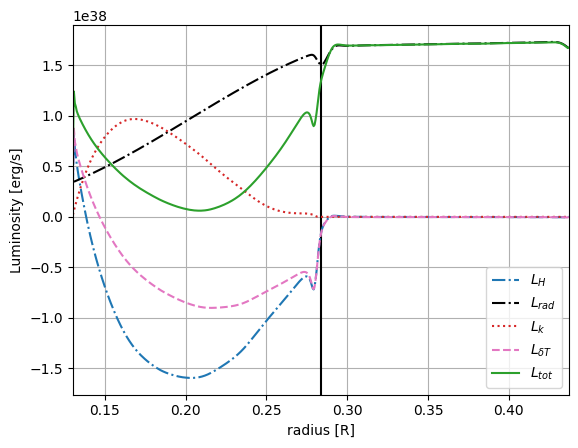

In [14]:
fig, ax = plt.subplots()
ax.axvline(r_env_init / r_tot, c="k")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_heat_instant"], c="tab:blue", ls="dashdot", label=r"$L_H$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_rad"], c="k", ls="dashdot", label=r"$L_{rad}$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_e_kin"], c="tab:red", ls="dotted", label=r"$L_k$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * all_data["flux_enthalpy"], c="tab:pink", ls="dashed", label=r"$L_{\delta T}$")
ax.plot(all_data["radius"] / r_tot, 4 * np.pi * (all_data["radius"] ** 2) * (all_data["flux_heat_instant"] + all_data["flux_rad"] + all_data["flux_e_kin"]), c="tab:green", label=r"$L_{tot}$")
ax.grid()
ax.set_xlim(r_bot / r_tot, r_top / r_tot)
ax.set_xlabel("radius [R]")
ax.set_ylabel("Luminosity [erg/s]")
ax.legend()
plt.savefig(save_dir + "luminosities.png")

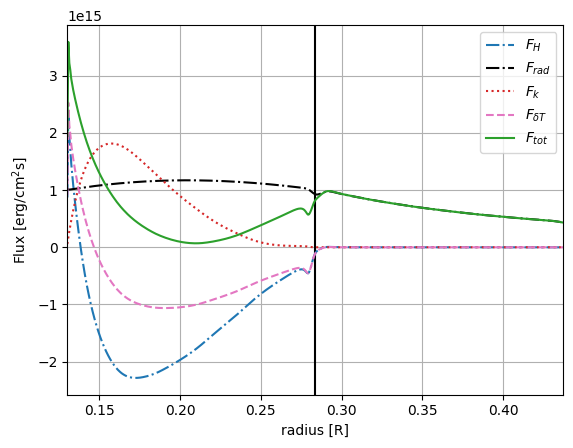

In [15]:
fig, ax = plt.subplots()
ax.axvline(r_env_init / r_tot, c="k")
ax.plot(all_data["radius"] / r_tot, all_data["flux_heat_instant"], c="tab:blue", ls="dashdot", label=r"$F_H$")
ax.plot(all_data["radius"] / r_tot, all_data["flux_rad"], c="k", ls="dashdot", label=r"$F_{rad}$")
ax.plot(all_data["radius"] / r_tot, all_data["flux_e_kin"], c="tab:red", ls="dotted", label=r"$F_k$")
ax.plot(all_data["radius"] / r_tot, all_data["flux_enthalpy"], c="tab:pink", ls="dashed", label=r"$F_{\delta T}$")
ax.plot(all_data["radius"] / r_tot, (all_data["flux_heat_instant"] + all_data["flux_rad"] + all_data["flux_e_kin"]), c="tab:green", label=r"$F_{tot}$")
ax.grid()
ax.set_xlim(r_bot / r_tot, r_top / r_tot)
ax.set_xlabel("radius [R]")
ax.set_ylabel(r"Flux [erg/cm$^2$s]")
ax.legend()
plt.savefig(save_dir + "fluxes.png")

# Oh my!